<a href="https://colab.research.google.com/github/manyaAM123/deep_learning/blob/main/exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Conv2DTranspose,
    concatenate
)

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = (
        tf.reduce_sum(y_true_f)
        + tf.reduce_sum(y_pred_f)
        - intersection
    )

    return (intersection + smooth) / (union + smooth)

In [ ]:
import os
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset configuration
IMG_SIZE = (128, 128)
BATCH_SIZE = 4
NUM_TEST_IMAGES = 50

print("Loading and preparing dataset via TFDS...")

# Load both training and testing splits from cats_vs_dogs safely
(ds_train, ds_test), info = tfds.load(
    'cats_vs_dogs',
    split=['train[:200]', 'train[200:250]'],
    with_info=True,
    as_supervised=False
)

def preprocess_segmentation_mock(example):
    image = tf.image.resize(example['image'], IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    # Create binary mask for U-Net pipeline testing
    gray = tf.image.rgb_to_grayscale(image)
    mask = tf.cast(gray > 0.5, tf.float32)

    return image, mask

# Create the optimized training dataset pipeline with prefetching
train_dataset = (
    ds_train
    .map(preprocess_segmentation_mock, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training dataset successfully batched, prefetched, and ready!")

# Create the testing dataset pipeline
test_dataset = (
    ds_test
    .take(NUM_TEST_IMAGES)
    .map(preprocess_segmentation_mock, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and testing datasets are fully ready!")

Loading and preparing dataset via TFDS...
Training dataset successfully batched, prefetched, and ready!
Training and testing datasets are fully ready!


In [ ]:
def create_segmentation_generator(image_dir, mask_dir, batch_size=4):
    """
    Creates a generator that yields paired image and mask batches.
    Adapted for MedPlant dataset where images and masks are in separate directories.
    """

    # Get sorted list of image files
    image_files = sorted(
        glob.glob(os.path.join(image_dir, "*.jpg")) +
        glob.glob(os.path.join(image_dir, "*.png"))
    )

    if not image_files:
        raise ValueError(f"No images found in {image_dir}")

    # Verify corresponding masks exist
    mask_files = []
    for img_file in image_files:
        base_name = os.path.basename(img_file)
        mask_file = os.path.join(mask_dir, base_name)
        if os.path.exists(mask_file):
            mask_files.append(mask_file)
        else:
            print(f"Warning: No mask found for {img_file}")

    print(f"Found {len(image_files)} images and {len(mask_files)} masks")

    if len(mask_files) == 0:
        raise ValueError(f"No matching masks found in {mask_dir}")

    # Generator function
    def generator():
        idx = 0
        while True:
            batch_images = []
            batch_masks = []
            for _ in range(batch_size):
                if idx >= len(image_files):
                    idx = 0  # Loop back to start

                # Load image
                img = tf.keras.preprocessing.image.load_img(
                    image_files[idx],
                    target_size=(128, 128),
                    color_mode='grayscale'
                )

                img_array = tf.keras.preprocessing.image.img_to_array(img)
                img_array = img_array / 255.0  # Normalize
                batch_images.append(img_array)                # Load corresponding mask
                if idx < len(mask_files):
                    mask = tf.keras.preprocessing.image.load_img(
                        mask_files[idx],
                        target_size=(128, 128),
                        color_mode='grayscale'
                    )

                    mask_array = tf.keras.preprocessing.image.img_to_array(mask)
                    mask_array = mask_array / 255.0  # Normalize
                    batch_masks.append(mask_array)

                idx += 1

            yield (np.array(batch_images), np.array(batch_masks))

    return generator()

In [ ]:
batch_size = 4

# Map your tf.data datasets to the generator variable names
train_gen = train_dataset
test_gen = test_dataset

print("train_gen and test_gen are successfully assigned!")

train_gen and test_gen are successfully assigned!


In [ ]:
def build_unet(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    c4 = Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    c5 = Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)
    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)
    u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

    outputs = Conv2D(1, 1, activation='sigmoid')(c9)

    model = Model(inputs, outputs)
    return model

In [ ]:
model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[dice_coef, jaccard_index]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_75 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_76 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_75[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_15    │ (None, 64, 64,    │          0 │ conv2d_76[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_77 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_15… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_78 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_77[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_16    │ (None, 32, 32,    │          0 │ conv2d_78[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_79 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_16… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_80 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_79[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_17    │ (None, 16, 16,    │          0 │ conv2d_80[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_81 (Conv2D)  │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_17… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_82 (Conv2D)  │ (None, 16, 16,    │  2,359,808 │ conv2d_81[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_18    │ (None, 8, 8, 512) │          0 │ conv2d_82[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_83 (Conv2D)  │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_18… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_84 (Conv2D)  │ (None, 8, 8,      │  9,438,208 │ conv2d_83[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_16 │ (None, 16, 16,    │  2,097,664 │ conv2d_84[0][0]   │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_16      │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
steps_train = 200  # Depends on dataset size
steps_test = 50

history = model.fit(
    train_gen,
    steps_per_epoch=steps_train,
    validation_data=test_gen,
    validation_steps=steps_test,
    epochs=1
)

200/200 ━━━━━━━━━━━━━━━━━━━━ 26s 51ms/step - dice_coef: 0.5242 - jaccard_index: 0.3594 - loss: 0.6085 - val_dice_coef: 0.6654 - val_jaccard_index: 0.5024 - val_loss: 0.3860


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step


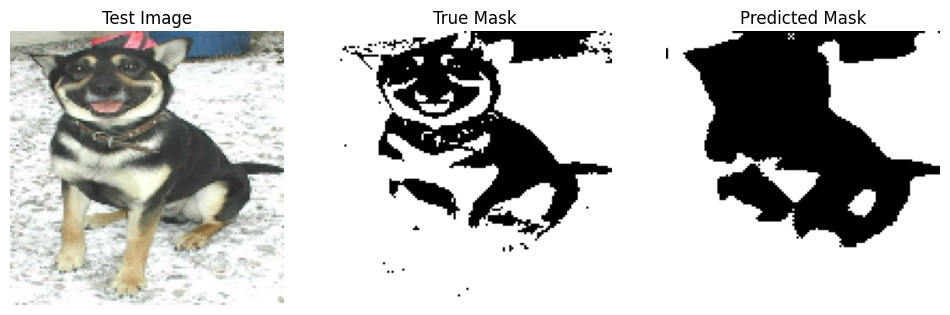

In [ ]:
# Fetch the next batch and generate new predictions
test_imgs, test_masks = next(iter(test_gen))
pred = model.predict(test_imgs)
pred_bin = (pred > 0.5).astype("float32")

# Pick a different index from the batch (e.g., index 1, 2, or 3)
idx = 1

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Test Image")
plt.imshow(test_imgs[idx].numpy().squeeze())
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("True Mask")
plt.imshow(test_masks[idx].numpy().squeeze(), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Predicted Mask")
plt.imshow(pred_bin[idx].squeeze(), cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
from tensorflow.keras.layers import multiply, Add, Activation, BatchNormalization

def attention_gate(f, g, inter_channel):
    theta_x = Conv2D(inter_channel, 1, strides=1, padding='same', use_bias=True)(f)
    phi_g = Conv2D(inter_channel, 1, strides=1, padding='same', use_bias=True)(g)

    # Use capital Add() here
    concat_xg = Add()([theta_x, phi_g])
    act_xg = Activation('relu')(concat_xg)

    psi = Conv2D(1, 1, strides=1, padding='same', use_bias=True)(act_xg)
    sigmoid_xg = Activation('sigmoid')(psi)

    return multiply([f, sigmoid_xg])

def build_attention_unet(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    # Encoder (Downsampling)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    c4 = Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    # Bottleneck
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(c5)

    # Decoder with Attention Gates on Skip Connections
    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    att6 = attention_gate(c4, u6, inter_channel=256)
    u6 = concatenate([u6, att6])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    att7 = attention_gate(c3, u7, inter_channel=128)
    u7 = concatenate([u7, att7])
    c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    att8 = attention_gate(c2, u8, inter_channel=64)
    u8 = concatenate([u8, att8])
    c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)

    u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    att9 = attention_gate(c1, u9, inter_channel=32)
    u9 = concatenate([u9, att9])
    c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

    outputs = Conv2D(1, 1, activation='sigmoid')(c9)

    model = Model(inputs, outputs)
    return model

# Instantiate and compile the Attention U-Net model
model = build_attention_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[dice_coef, jaccard_index]
)
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_108 (Conv2D) │ (None, 128, 128,  │      1,792 │ input_layer_7[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_109 (Conv2D) │ (None, 128, 128,  │     36,928 │ conv2d_108[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_23    │ (None, 64, 64,    │          0 │ conv2d_109[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_110 (Conv2D) │ (None, 64, 64,    │     73,856 │ max_pooling2d_23… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_111 (Conv2D) │ (None, 64, 64,    │    147,584 │ conv2d_110[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_24    │ (None, 32, 32,    │          0 │ conv2d_111[0][0]  │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_112 (Conv2D) │ (None, 32, 32,    │    295,168 │ max_pooling2d_24… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_113 (Conv2D) │ (None, 32, 32,    │    590,080 │ conv2d_112[0][0]  │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_25    │ (None, 16, 16,    │          0 │ conv2d_113[0][0]  │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_114 (Conv2D) │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_25… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_115 (Conv2D) │ (None, 16, 16,    │  2,359,808 │ conv2d_114[0][0]  │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_26    │ (None, 8, 8, 512) │          0 │ conv2d_115[0][0]  │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_116 (Conv2D) │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_26… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_117 (Conv2D) │ (None, 8, 8,      │  9,438,208 │ conv2d_116[0][0]  │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_21 │ (None, 16, 16,    │  2,097,664 │ conv2d_117[0][0]  │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_118 (Conv2D) │ (None, 16, 16,    │    131,328 │ conv2d_115[0][0]

 Total params: 31,381,349 (119.71 MB)

 Trainable params: 31,381,349 (119.71 MB)

 Non-trainable params: 0 (0.00 B)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


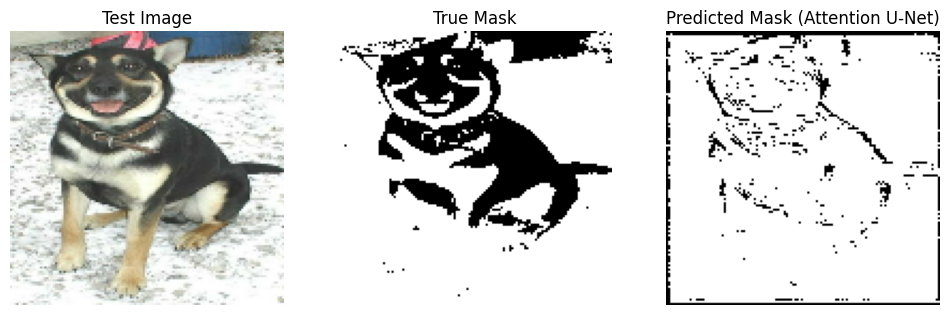

In [ ]:
# 1. Fetch a batch from your test dataset generator
test_imgs, test_masks = next(iter(test_gen))

# 2. Generate predictions using your Attention U-Net model
pred = model.predict(test_imgs)
pred_bin = (pred > 0.5).astype("float32")

# 3. Choose the index from the batch (e.g., 0, 1, 2, or 3)
idx = 1

# 4. Plot the comparison side-by-side
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Test Image")
plt.imshow(test_imgs[idx].numpy().squeeze())
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("True Mask")
plt.imshow(test_masks[idx].numpy().squeeze(), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Predicted Mask (Attention U-Net)")
plt.imshow(pred_bin[idx].squeeze(), cmap='gray')
plt.axis('off')

plt.show()